# Data Leakage and Robust Validation Design

**What you'll learn**

- Recognize the five big leakage families — post-outcome features, preprocessing
  contamination, temporal leakage, group leakage, and target-encoding leakage — and
  reproduce each as a runnable failure case with known ground truth.
- Quantify how much each leak inflates offline metrics versus an honest evaluation
  (collected in a single "damage report" table at the end).
- Make preprocessing leakage structurally impossible with `Pipeline` + `ColumnTransformer`:
  everything that learns from data gets fit inside the CV folds.
- Choose a validation scheme — `KFold` / `StratifiedKFold` / `GroupKFold` /
  `TimeSeriesSplit` / nested CV — from the structure of your data and your deployment.
- Implement adversarial validation to detect train/test distribution shift before
  production detects it for you.

**Why it matters in interviews**

- "Your CV says 0.95 AUC, production says 0.70 — debug it" is a staple senior-level
  screen. Interviewers want a systematic checklist, not a shrug.
- Case rounds on churn or fraud almost always probe how you would split the data;
  random K-fold on time-ordered, per-user data is an instant red flag.
- "Tell me about a model that looked great offline and failed in production" — leakage
  is the most common honest answer, and you need the taxonomy and vocabulary to tell it well.
- Target encoding, group-aware CV, and nested CV are favorite rapid-fire probes for
  tabular-ML roles.

Everything here is simulated so that we *know* the truth: when a model on pure noise
scores 0.8 AUC, there is no philosophical debate about whether the estimate is inflated.

## Setup

In [1]:
import os

# Keep numeric thread pools modest so the run is fast and predictable on small machines.
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    KFold,
    StratifiedGroupKFold,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder

rng = np.random.default_rng(42)

plt.rcParams.update(
    {
        "figure.figsize": (8.5, 4.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
sns.set_palette("deep")


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


# One shuffled, stratified 5-fold splitter reused throughout.
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Every demo appends its inflated-vs-honest numbers here; we tabulate them at the end.
leakage_summary = []


def record(leakage_type, inflated, honest, production=np.nan):
    leakage_summary.append(
        {
            "leakage_type": leakage_type,
            "inflated_estimate": inflated,
            "honest_estimate": honest,
            "production_reality": production,
        }
    )

## 1. A taxonomy of leakage

**Leakage** = the model (or the evaluation) uses information that will not be available —
or will be distributed differently — at prediction time. The symptom is always the same:
the offline estimate overstates production performance. The mechanisms differ, and each
mechanism has a different fix, which is why the taxonomy is worth memorizing:

| # | Leakage type | Mechanism | Classic tell | Structural fix |
|---|--------------|-----------|--------------|----------------|
| 1 | **Target leakage** (post-outcome feature) | A feature is caused by, or recorded after, the outcome | One feature with absurd univariate AUC; importance dominated by one column | Point-in-time feature discipline: "was this value known *before* the prediction moment?" |
| 2 | **Preprocessing contamination** | Scaler / imputer / feature selector / encoder fit on data that later serves as test | "We preprocessed, *then* split" anywhere in the code | Fit every learned transform inside the folds (`Pipeline`) |
| 3 | **Temporal leakage** | Random splits let the model train on the future and predict the past | Metrics degrade every time the model meets a genuinely new week | Time-based splits that mirror deployment |
| 4 | **Group leakage** | Rows of the same entity (user, patient, device) straddle train and test | Metrics collapse on genuinely new users | `GroupKFold` with group = entity |
| 5 | **Target-encoding leakage** | Category encoded with label statistics that include the row's own label | High-cardinality ID-like features near the top of importance | Out-of-fold encoding, encoder fit inside the pipeline |

Honorable mentions that show up constantly in real code reviews: duplicate rows straddling
a split, resampling/SMOTE applied before splitting, early stopping monitored on the test
fold, and one holdout reused for dozens of decisions. We hit the first two in the
Pitfalls section; early stopping hygiene is covered in
[01_gradient_boosting_mastery.ipynb](01_gradient_boosting_mastery.ipynb).

A key distinction to carry through this notebook:

- Leaks **in the data** (type 1) inflate *every* offline split — CV cannot catch them.
  You catch them with domain reasoning about timestamps and with detection heuristics.
- Leaks **in the procedure** (types 2–5) are caught (and fixed) by getting the split
  design right and fitting everything inside the folds.

## 2. Leak 1 — target leakage via a post-outcome feature

Setting: subscription churn. We predict, at the start of the month, whether an account
churns during that month. The warehouse also stores `called_retention_line` — a flag set
when the customer phones in to cancel. Historically it is populated for most churners,
because calling *is how you churn*. It is a **consequence of the outcome**, not a
predictor of it. At scoring time (start of month), nobody has called yet: the field is 0
for everyone.

Note what happens below: the leaky feature inflates the estimate *on a perfectly clean
random train/test split*. No split hygiene can save you here — the leak lives inside the
feature matrix.

In [2]:
n1 = 20_000
tenure_months = rng.gamma(shape=2.0, scale=12.0, size=n1)
usage_hours = rng.gamma(shape=2.0, scale=10.0, size=n1)
tickets_90d = rng.poisson(0.8, size=n1)
plan_pro = rng.binomial(1, 0.35, size=n1)

logit_churn = (
    -0.4
    - 0.030 * tenure_months
    - 0.055 * usage_hours
    + 0.40 * tickets_90d
    - 0.60 * plan_pro
)
churned = rng.binomial(1, sigmoid(logit_churn))

# The post-outcome feature: ~70% of churners called to cancel; ~3% of retained
# customers called about something and got routed to retention.
called_retention_line = np.where(
    churned == 1, rng.binomial(1, 0.70, size=n1), rng.binomial(1, 0.03, size=n1)
)

df1 = pd.DataFrame(
    {
        "tenure_months": tenure_months,
        "usage_hours": usage_hours,
        "tickets_90d": tickets_90d,
        "plan_pro": plan_pro,
        "called_retention_line": called_retention_line,
        "churned": churned,
    }
)
print(f"n = {n1:,}, churn rate = {df1['churned'].mean():.3f}")

n = 20,000, churn rate = 0.143


In [3]:
feat_honest = ["tenure_months", "usage_hours", "tickets_90d", "plan_pro"]
feat_leaky = feat_honest + ["called_retention_line"]

train1, test1 = train_test_split(
    df1, test_size=0.30, stratify=df1["churned"], random_state=42
)

# Model WITH the leaky feature: what the offline eval claims.
gbm_leaky = HistGradientBoostingClassifier(random_state=42)
gbm_leaky.fit(train1[feat_leaky], train1["churned"])
auc_leaky_offline = roc_auc_score(
    test1["churned"], gbm_leaky.predict_proba(test1[feat_leaky])[:, 1]
)

# Production reality: at scoring time the flag is 0 for everyone (nobody has called yet).
test1_prod = test1.copy()
test1_prod["called_retention_line"] = 0
auc_leaky_production = roc_auc_score(
    test1["churned"], gbm_leaky.predict_proba(test1_prod[feat_leaky])[:, 1]
)

# Honest model: the leaky feature never enters.
gbm_honest = HistGradientBoostingClassifier(random_state=42)
gbm_honest.fit(train1[feat_honest], train1["churned"])
auc_honest_1 = roc_auc_score(
    test1["churned"], gbm_honest.predict_proba(test1[feat_honest])[:, 1]
)

print(f"Offline test AUC, leaky feature included : {auc_leaky_offline:.3f}   <- what you report")
print(f"Production AUC of that same model        : {auc_leaky_production:.3f}   <- what you ship")
print(f"Honest model (leaky feature dropped)     : {auc_honest_1:.3f}")

record("1. Target leakage (post-outcome feature)", auc_leaky_offline, auc_honest_1, auc_leaky_production)

Offline test AUC, leaky feature included : 0.898   <- what you report
Production AUC of that same model        : 0.707   <- what you ship
Honest model (leaky feature dropped)     : 0.717


Two distinct costs, visible in three numbers. The offline report overstates production
reality by ~0.19 of AUC. And the model that ships is *no better* than — here, slightly
worse than — the honest model, because gradient boosting leaned on the dominant leaky
flag at the expense of legitimate signal. Target leakage inflates the report **and**
degrades the artifact; Section 6's naive target encoding shows the same double cost more
dramatically.

**Detection heuristic**: scan univariate AUCs. A single feature that nearly matches the
full model's performance deserves interrogation ("what process writes this column, and
*when*?").

In [4]:
print("Univariate AUC per feature (train):")
for col in feat_leaky:
    auc = roc_auc_score(train1["churned"], train1[col])
    print(f"  {col:>22s}: {max(auc, 1 - auc):.3f}")

Univariate AUC per feature (train):
           tenure_months: 0.615
             usage_hours: 0.656
             tickets_90d: 0.596
                plan_pro: 0.561
   called_retention_line: 0.841


## 3. Leak 2 — preprocessing contamination

The classic code smell: *"we imputed, scaled, and selected features on the full dataset,
then split"*. Every statistic estimated from data that later serves as test data
contaminates the evaluation. How bad it is depends on **what the step gets to see**:

- Steps that see only **X** (mean-imputer, scaler): mild contamination when rows are
  i.i.d. — the test fold nudges a mean/variance estimate, which is smooth and low-information.
- Steps that see **y** (supervised feature selection, target encoding, resampling):
  potentially catastrophic — they can smuggle the labels themselves across the split.

We quantify both on **pure noise** (1,000 features, 240 rows, 10% missing values, labels
independent of everything). Ground truth AUC is exactly 0.5, so any excess is leakage.

In [5]:
n2, p2 = 240, 1_000
X_noise = rng.normal(size=(n2, p2))
X_noise[rng.random((n2, p2)) < 0.10] = np.nan  # 10% missing completely at random
y_noise = rng.binomial(1, 0.5, size=n2)

logreg = LogisticRegression(max_iter=2_000)

# --- CONTAMINATED, unsupervised only: impute + scale on ALL rows, then cross-validate
X_prep_all = StandardScaler().fit_transform(
    SimpleImputer(strategy="mean").fit_transform(X_noise)
)
auc_contam_scale = cross_val_score(
    logreg, X_prep_all, y_noise, cv=cv5, scoring="roc_auc"
).mean()

# --- HONEST, unsupervised only: impute + scale fit inside each fold
pipe_scale = Pipeline(
    [
        ("impute", SimpleImputer(strategy="mean")),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2_000)),
    ]
)
auc_honest_scale = cross_val_score(
    pipe_scale, X_noise, y_noise, cv=cv5, scoring="roc_auc"
).mean()

print("Unsupervised steps only (imputer + scaler), ground truth = 0.500:")
print(f"  fit on all data, then CV : {auc_contam_scale:.3f}")
print(f"  fit inside folds         : {auc_honest_scale:.3f}")
print(f"  inflation                : {auc_contam_scale - auc_honest_scale:+.3f}")

Unsupervised steps only (imputer + scaler), ground truth = 0.500:
  fit on all data, then CV : 0.516
  fit inside folds         : 0.519
  inflation                : -0.002


In [6]:
# --- CONTAMINATED, supervised step added: select the top 20 of 1,000 features BY
#     LOOKING AT y on all 240 rows, then cross-validate on the selected columns.
selector = SelectKBest(f_classif, k=20).fit(X_prep_all, y_noise)
X_selected = selector.transform(X_prep_all)
auc_contam_select = cross_val_score(
    logreg, X_selected, y_noise, cv=cv5, scoring="roc_auc"
).mean()

# --- HONEST: the selector is fit inside each training fold
pipe_select = Pipeline(
    [
        ("impute", SimpleImputer(strategy="mean")),
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_classif, k=20)),
        ("clf", LogisticRegression(max_iter=2_000)),
    ]
)
auc_honest_select = cross_val_score(
    pipe_select, X_noise, y_noise, cv=cv5, scoring="roc_auc"
).mean()

print("With supervised feature selection (top 20 of 1,000), ground truth = 0.500:")
print(f"  selector fit on all data : {auc_contam_select:.3f}")
print(f"  selector fit inside folds: {auc_honest_select:.3f}")
print(f"  inflation                : {auc_contam_select - auc_honest_select:+.3f}")

record(
    "2. Preprocessing contamination (selection on all data)",
    auc_contam_select,
    auc_honest_select,
    0.500,  # ground truth: the data are pure noise
)

With supervised feature selection (top 20 of 1,000), ground truth = 0.500:
  selector fit on all data : 0.812
  selector fit inside folds: 0.460
  inflation                : +0.352


The senior-level takeaway is the **severity gradient**, not a blanket rule:

- Imputer/scaler contamination on i.i.d. data moved the estimate by roughly nothing —
  which is why people get away with it, and why they then get burned when they apply the
  same "preprocess first" habit to a step that touches `y`.
- Supervised selection fit on all data turned pure noise into a strong-looking model.
  This is the famous "wrong way to do cross-validation" from Hastie et al. (*Elements of
  Statistical Learning*, ch. 7.10.2), and it still ships to production regularly.
- The cost of doing it right is one `Pipeline`. There is no performance argument for the
  contaminated version — only convenience. Section 8 makes this the default habit.

## 4. Leak 3 — temporal leakage: random splits on time-ordered churn data

Churn data is a time series of cohorts, not an i.i.d. sample: base rates drift with
pricing changes, competitors, seasonality. We simulate 24 months of monthly churn
observations with

- a **drifting month effect** on churn (random walk) — think unobserved market conditions,
- a **drifting engagement distribution** (AR(1) market shock) — this is covariate shift
  that adversarial validation will detect in Section 10,
- stationary row-level signal (engagement, tickets, tenure) that genuinely generalizes.

The feature set includes two innocuous-looking columns that make random CV lie:
the calendar `month` index and `month_avg_engagement` (a month-level aggregate — the
kind of feature every feature store serves). Under a shuffled split, both act as **month
fingerprints**: the model looks up each month's base rate because it has seen other rows
from the very same month in training. In production the model faces months it has never
seen — no lookup available.

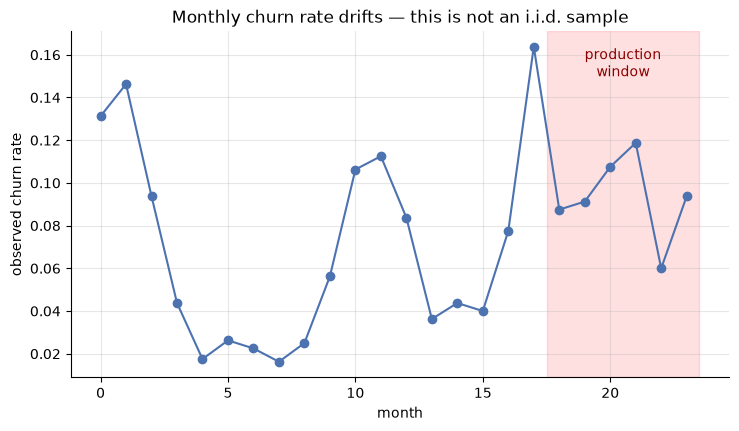

In [7]:
n_months, users_per_month = 24, 800
month = np.repeat(np.arange(n_months), users_per_month)
n3 = month.size

market_shock = np.zeros(n_months)  # drives engagement levels (covariate drift)
month_effect = np.zeros(n_months)  # drives churn base rate (unobserved concept drift)
for t in range(1, n_months):
    market_shock[t] = 0.85 * market_shock[t - 1] + rng.normal(0, 0.6)
    month_effect[t] = month_effect[t - 1] + rng.normal(0, 0.45)

engagement = 30 + 4.0 * market_shock[month] + rng.normal(0, 6.0, size=n3)
tenure3 = rng.gamma(2.0, 10.0, size=n3)
tickets3 = rng.poisson(0.7, size=n3)

logit3 = (
    -2.0
    + month_effect[month]
    - 0.09 * (engagement - 30)
    + 0.35 * tickets3
    - 0.025 * tenure3
)
churned3 = rng.binomial(1, sigmoid(logit3))

df3 = pd.DataFrame(
    {
        "month": month,
        "engagement": engagement,
        "tenure": tenure3,
        "tickets": tickets3,
        "churned": churned3,
    }
)
df3["month_avg_engagement"] = df3.groupby("month")["engagement"].transform("mean")
df3 = df3.sort_values("month", kind="stable").reset_index(drop=True)

monthly = df3.groupby("month")["churned"].mean()
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly.values, marker="o")
ax.axvspan(17.5, 23.5, alpha=0.12, color="red")
ax.text(20.5, monthly.max(), "production\nwindow", ha="center", va="top", color="darkred")
ax.set_xlabel("month")
ax.set_ylabel("observed churn rate")
ax.set_title("Monthly churn rate drifts — this is not an i.i.d. sample")
plt.show()

In [8]:
features3 = ["month", "engagement", "month_avg_engagement", "tenure", "tickets"]
dev3 = df3[df3["month"] < 18]   # what we have at model-building time
prod3 = df3[df3["month"] >= 18]  # the future the model will actually face

gbm3 = HistGradientBoostingClassifier(random_state=42)

# WRONG: shuffled 5-fold CV on the development window
auc_random_split = cross_val_score(
    gbm3, dev3[features3], dev3["churned"], cv=cv5, scoring="roc_auc"
).mean()

# RIGHT: expanding-window time-based CV (dev3 is sorted by month);
# 5 folds, each testing on the next ~2 months after an expanding training window
auc_time_split = cross_val_score(
    gbm3, dev3[features3], dev3["churned"],
    cv=TimeSeriesSplit(n_splits=5, test_size=1600),
    scoring="roc_auc",
).mean()

# Reality: train on months 0-17, score months 18-23
gbm3.fit(dev3[features3], dev3["churned"])
auc_forward = roc_auc_score(
    prod3["churned"], gbm3.predict_proba(prod3[features3])[:, 1]
)

print(f"Shuffled 5-fold CV estimate     : {auc_random_split:.3f}   <- interpolates within known months")
print(f"Time-based CV estimate          : {auc_time_split:.3f}   <- must extrapolate, like production")
print(f"Actual forward performance      : {auc_forward:.3f}")

record("3. Temporal leakage (random split on time-ordered data)",
       auc_random_split, auc_time_split, auc_forward)

Shuffled 5-fold CV estimate     : 0.731   <- interpolates within known months
Time-based CV estimate          : 0.621   <- must extrapolate, like production
Actual forward performance      : 0.639


The time-based estimate lands within ~0.02 of forward reality (slightly *below* it —
expanding-window folds train on less history than the final model, so honest time-based
CV errs a touch conservative). The shuffled estimate overshoots reality by ~0.09.
Two things are worth saying precisely in an interview:

1. Random CV is answering the wrong question — "how well do I predict *held-out rows from
   months I trained on*?" Production asks "how well do I predict *months I have never seen*?"
2. The worst offenders are often **aggregate features** (`month_avg_engagement`) and raw
   calendar indices, because trees use them as period identifiers. The features are not
   "wrong" — the *split* is what turns them into leaks.

Full rolling-origin backtesting, gaps/embargoes for label latency, and horizon-dependent
error curves are developed in
[../05_time_series/03_ml_forecasting_backtesting.ipynb](../05_time_series/03_ml_forecasting_backtesting.ipynb);
the finance version of this failure (backtest overfitting) is in
[../09_finance_and_operations/02_returns_risk.ipynb](../09_finance_and_operations/02_returns_risk.ipynb).

## 5. Leak 4 — group leakage: the same user in train and test

Panel data: 300 accounts observed for 20 months each, predicting a recurring event
(`downgrade_next_month`). Two ingredients make row-wise splits lie:

- a **latent account trait** drives the outcome month after month (labels are correlated
  within account), and
- each account carries **stable descriptors** (`acct_attr_*`: firmographics, channel,
  device mix). By construction these have **no true relationship** with the outcome
  across accounts — they are pure account fingerprints.

A flexible model + row-wise KFold = the model *identifies the account* from its
fingerprint in the test fold, having memorized that account's base rate from its other
rows in the training folds. `GroupKFold(group=account)` simulates what production
actually faces — accounts the model has never seen.

In [9]:
n_users, months_per_user = 300, 20
user_id = np.repeat(np.arange(n_users), months_per_user)
n4 = user_id.size

user_trait = rng.normal(0, 1, size=n_users)        # latent account health
acct_attrs = rng.normal(0, 1, size=(n_users, 8))   # stable descriptors, NO true effect

sessions = rng.normal(0, 1, size=n4)               # row-level behavior, real effect
logit4 = -1.3 + 1.5 * user_trait[user_id] + 0.70 * sessions
y4 = rng.binomial(1, sigmoid(logit4))

X4 = pd.DataFrame(
    acct_attrs[user_id] + rng.normal(0, 0.02, size=(n4, 8)),  # tiny measurement noise
    columns=[f"acct_attr_{i}" for i in range(1, 9)],
)
X4["sessions_this_month"] = sessions

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

auc_row_kfold = cross_val_score(
    rf, X4, y4, cv=cv5, scoring="roc_auc"
).mean()
auc_group_kfold = cross_val_score(
    rf, X4, y4, cv=GroupKFold(n_splits=5), groups=user_id, scoring="roc_auc"
).mean()

print(f"event rate = {y4.mean():.3f}, rows = {n4:,}, accounts = {n_users}")
print(f"Row-wise StratifiedKFold AUC : {auc_row_kfold:.3f}   <- memorizes accounts via their fingerprints")
print(f"GroupKFold (by account) AUC  : {auc_group_kfold:.3f}   <- what you get on NEW accounts")

record("4. Group leakage (same user in train & test)", auc_row_kfold, auc_group_kfold)

event rate = 0.267, rows = 6,000, accounts = 300
Row-wise StratifiedKFold AUC : 0.761   <- memorizes accounts via their fingerprints
GroupKFold (by account) AUC  : 0.607   <- what you get on NEW accounts


Under the grouped split only `sessions_this_month` generalizes — the fingerprints are
worthless on unseen accounts, exactly as the data-generating process says they should be.
Row-wise CV instead credits the model for **entity memorization**.

This is the "patient ID leak" that has invalidated published medical-imaging results and
countless Kaggle silver medals (same speaker/patient/device in both sets). The question
to ask: *at serving time, will I score entities that contributed rows to training?* If
the answer is "no" (new users) or "not this way", the split must keep entities intact.
When you need groups **and** label stratification, `StratifiedGroupKFold` handles both —
see Exercise 1.

## 6. Leak 5 — naive target encoding vs out-of-fold target encoding

High-cardinality categoricals (campaign IDs, zip codes, merchant IDs, SKUs) invite
mean-target encoding: replace the category with the mean outcome of that category. Done
naively — encode using statistics computed on the *same rows you then train/validate
on* — each row's own label sneaks into its own feature. A level with $n_c$ rows gives
each of its rows a feature containing $1/n_c$ of its own label; campaign sizes follow
the usual long tail, so for the median campaign (a handful of rows) that is a direct
label pipe — and a boosted tree will happily drink from it.

Setting: churn with 1,000 acquisition campaigns whose true effects are modest, plus weak
numeric features. We compare, against a properly held-out set:

- **naive**: encode with per-campaign means from the full training set, then cross-validate
  on that same training set;
- **out-of-fold (OOF)**: each row is encoded using label statistics from *other* folds
  only, with smoothing toward the global rate.

In [10]:
n5, n_campaigns = 12_000, 1_000
# Long-tailed campaign sizes: a few huge campaigns, many tiny ones (as in real ad data).
camp_weights = rng.lognormal(0, 1.2, size=n_campaigns)
campaign = rng.choice(n_campaigns, size=n5, p=camp_weights / camp_weights.sum())
campaign_effect = rng.normal(0, 0.35, size=n_campaigns)  # modest true effects

ad_spend = rng.normal(0, 1, size=n5)
visits = rng.normal(0, 1, size=n5)
nps = rng.normal(0, 1, size=n5)
nps[rng.random(n5) < 0.25] = np.nan  # realistic missingness (used again in Section 8)

logit5 = (
    -1.3
    + campaign_effect[campaign]
    + 0.50 * ad_spend
    + 0.40 * visits
    + 0.30 * np.nan_to_num(nps)
)
df5 = pd.DataFrame(
    {
        "campaign": pd.Series(campaign).map(lambda c: f"camp_{c:04d}"),
        "ad_spend": ad_spend,
        "visits": visits,
        "nps": nps,
        "churned": rng.binomial(1, sigmoid(logit5)),
    }
)

train5, hold5 = train_test_split(
    df5, test_size=1 / 3, stratify=df5["churned"], random_state=42
)
counts5 = train5["campaign"].value_counts()
print(f"train {len(train5):,} rows, holdout {len(hold5):,} rows, "
      f"{train5['campaign'].nunique()} campaigns seen in train")
print(f"campaign size in train: median {counts5.median():.0f}, "
      f"p90 {counts5.quantile(0.90):.0f}, max {counts5.max()}")

train 8,000 rows, holdout 4,000 rows, 895 campaigns seen in train
campaign size in train: median 5, p90 20, max 131


In [11]:
num5 = ["ad_spend", "visits", "nps"]
prior5 = train5["churned"].mean()

# --- NAIVE: per-campaign mean over the whole training set, applied everywhere
naive_map = train5.groupby("campaign")["churned"].mean()
train5_naive = train5.assign(campaign_te=train5["campaign"].map(naive_map))
hold5_naive = hold5.assign(
    campaign_te=hold5["campaign"].map(naive_map).fillna(prior5)
)

gbm5 = HistGradientBoostingClassifier(random_state=42)  # NaNs handled natively
auc_te_naive_cv = cross_val_score(
    gbm5,
    train5_naive[["campaign_te"] + num5],
    train5_naive["churned"],
    cv=cv5,
    scoring="roc_auc",
).mean()
gbm5.fit(train5_naive[["campaign_te"] + num5], train5_naive["churned"])
auc_te_naive_hold = roc_auc_score(
    hold5["churned"], gbm5.predict_proba(hold5_naive[["campaign_te"] + num5])[:, 1]
)

print(f"NAIVE encoding — CV estimate : {auc_te_naive_cv:.3f}   <- what the naive workflow reports")
print(f"NAIVE encoding — holdout AUC : {auc_te_naive_hold:.3f}   <- what it actually delivers")

NAIVE encoding — CV estimate : 0.744   <- what the naive workflow reports
NAIVE encoding — holdout AUC : 0.633   <- what it actually delivers


In [12]:
def oof_target_encode(frame, col, target, n_splits=5, m=20.0, seed=42):
    """Out-of-fold mean-target encoding with additive smoothing toward the prior."""
    prior = frame[target].mean()
    encoded = np.full(len(frame), np.nan)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for fit_idx, enc_idx in kf.split(frame):
        stats = frame.iloc[fit_idx].groupby(col)[target].agg(["sum", "count"])
        smoothed = (stats["sum"] + m * prior) / (stats["count"] + m)
        encoded[enc_idx] = (
            frame.iloc[enc_idx][col].map(smoothed).fillna(prior).to_numpy()
        )
    return encoded, prior


def fit_encoding_map(frame, col, target, m=20.0):
    """Encoding map fit on a training frame, for transforming NEW data."""
    prior = frame[target].mean()
    stats = frame.groupby(col)[target].agg(["sum", "count"])
    return (stats["sum"] + m * prior) / (stats["count"] + m), prior


# --- OOF: each training row encoded without its own fold; holdout encoded from full train
oof_te, _ = oof_target_encode(train5, "campaign", "churned", m=20.0)
train5_oof = train5.assign(campaign_te=oof_te)
full_map, _ = fit_encoding_map(train5, "campaign", "churned", m=20.0)
hold5_oof = hold5.assign(campaign_te=hold5["campaign"].map(full_map).fillna(prior5))

gbm5b = HistGradientBoostingClassifier(random_state=42)
auc_te_oof_cv = cross_val_score(
    gbm5b,
    train5_oof[["campaign_te"] + num5],
    train5_oof["churned"],
    cv=cv5,
    scoring="roc_auc",
).mean()
gbm5b.fit(train5_oof[["campaign_te"] + num5], train5_oof["churned"])
auc_te_oof_hold = roc_auc_score(
    hold5["churned"], gbm5b.predict_proba(hold5_oof[["campaign_te"] + num5])[:, 1]
)

print(f"OOF encoding — CV estimate : {auc_te_oof_cv:.3f}")
print(f"OOF encoding — holdout AUC : {auc_te_oof_hold:.3f}")

record("5. Naive target encoding (vs out-of-fold)",
       auc_te_naive_cv, auc_te_oof_cv, auc_te_naive_hold)

OOF encoding — CV estimate : 0.643
OOF encoding — holdout AUC : 0.662


Same model class, same data, same holdout — the only difference is encoding hygiene:

- The naive workflow **overpromises** (inflated CV) and **underdelivers** (its holdout AUC
  is the worst of all four numbers, because the model learned to trust a feature whose
  informativeness evaporates on new data — the exact failure signature of Leak 1).
- The OOF workflow's CV estimate tracks its holdout performance to within ~0.02 — and
  errs in the *conservative* direction (fold encodings are fit on less data than the
  final one). That agreement — *estimate ≈ reality* — is the whole point of validation
  design.

Two refinements every senior candidate should know: **smoothing** (shrink rare-level
means toward the prior — Exercise 2 sweeps it) and the fact that a single OOF pass reused
across many modeling decisions still leaks a little through selection; the fully clean
version fits the encoder *inside* the pipeline, which is exactly what sklearn's
`TargetEncoder` does (Section 8).

## 7. The damage report

One table, five leaks. "Inflated" is what the leaky workflow reports, "honest" is what a
correct evaluation reports, and "production reality" is a genuinely untouched
future/holdout/ground truth where the demo has one.

In [13]:
summary_df = pd.DataFrame(leakage_summary)
summary_df["inflation"] = summary_df["inflated_estimate"] - summary_df["honest_estimate"]
summary_df.round(3)

,leakage_type,inflated_estimate,honest_estimate,production_reality,inflation
0,1. Target leakage (post-outcome feature),0.898,0.717,0.707,0.181
1,2. Preprocessing contamination (selection on a...,0.812,0.460,0.500,0.352
2,3. Temporal leakage (random split on time-orde...,0.731,0.621,0.639,0.109
3,4. Group leakage (same user in train & test),0.761,0.607,NaN,0.154
4,5. Naive target encoding (vs out-of-fold),0.744,0.643,0.633,0.101


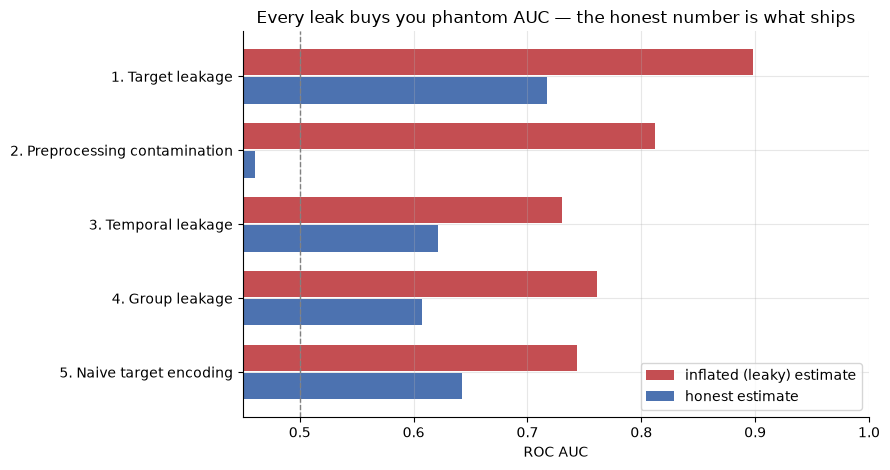

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ypos = np.arange(len(summary_df))
ax.barh(ypos - 0.19, summary_df["inflated_estimate"], height=0.36,
        label="inflated (leaky) estimate", color="#c44e52")
ax.barh(ypos + 0.19, summary_df["honest_estimate"], height=0.36,
        label="honest estimate", color="#4c72b0")
ax.set_yticks(ypos, [t.split("(")[0].strip() for t in summary_df["leakage_type"]])
ax.invert_yaxis()
ax.axvline(0.5, ls="--", lw=1, color="grey")
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("ROC AUC")
ax.set_title("Every leak buys you phantom AUC — the honest number is what ships")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. The structural fix: `Pipeline` + `ColumnTransformer`

Discipline fails; structure doesn't. The reliable fix for every *procedural* leak
(types 2–5) is the same: **make the split the outermost operation**. Every step that
learns anything from data — imputer, scaler, selector, encoder, model — lives inside one
estimator object, and `cross_val_score` clones and refits that whole object per fold.
Nothing fit on fold A can touch fold B, by construction. The same object is what you
ship, so train/serve skew from preprocessing drift disappears too (more on that in
[../10_ml_in_production/02_production_readiness.ipynb](../10_ml_in_production/02_production_readiness.ipynb)).

We rebuild the target-encoding example correctly. Note `TargetEncoder`: its
`fit_transform` uses **internal out-of-fold cross-fitting** for the training data — the
OOF scheme we hand-rolled above, productionized.

In [15]:
numeric_features = ["ad_spend", "visits", "nps"]

prep = ColumnTransformer(
    [
        (
            "num",
            Pipeline(
                [
                    ("impute", SimpleImputer(strategy="median")),
                    ("scale", StandardScaler()),
                ]
            ),
            numeric_features,
        ),
        (
            "campaign",
            TargetEncoder(
                target_type="binary",
                smooth=20.0,
                cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
            ),
            ["campaign"],
        ),
    ]
)
pipe = Pipeline(
    [("prep", prep), ("clf", HistGradientBoostingClassifier(random_state=42))]
)

X5_cols = ["campaign"] + numeric_features
auc_pipe_cv = cross_val_score(
    pipe, train5[X5_cols], train5["churned"], cv=cv5, scoring="roc_auc"
)
pipe.fit(train5[X5_cols], train5["churned"])
auc_pipe_hold = roc_auc_score(
    hold5["churned"], pipe.predict_proba(hold5[X5_cols])[:, 1]
)

print(f"Pipeline CV estimate : {auc_pipe_cv.mean():.3f} +/- {auc_pipe_cv.std():.3f}")
print(f"Pipeline holdout AUC : {auc_pipe_hold:.3f}")
print(f"(naive workflow claimed {auc_te_naive_cv:.3f} and delivered {auc_te_naive_hold:.3f})")

Pipeline CV estimate : 0.642 +/- 0.010
Pipeline holdout AUC : 0.666
(naive workflow claimed 0.744 and delivered 0.633)


In [16]:
pipe  # the entire learning procedure is one refittable, shippable object

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['campaign','ad_spend','visits','nps']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('campaign', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified

The pipeline's CV estimate lands within a few hundredths of holdout reality (erring
slightly conservative, as honest estimates tend to) — and the whole preprocessing debate
("is it OK to fit the scaler on all data?") becomes moot, because the right thing is now
also the easy thing. Habits that follow from this:

- `cross_val_score(pipeline, X_raw, y)` on **raw** columns; never on pre-transformed matrices.
- Feature selection, resampling, calibration: inside the pipeline or inside the folds. Always.
- One caveat `Pipeline` does *not* fix: features that are leaky **in the data** (Leak 1)
  and splits that ignore time or groups. Structure handles *how* you fit; you still must
  choose *where* to split — next section.

## 9. Choosing a validation scheme — the decision guide

The splitter is a **simulation of deployment**. Choose it by asking what will be new at
serving time: new rows? new entities? the future? all three?

```text
Will the model score data from LATER TIME than it trained on, in a world that drifts?
├─ yes, and rows also cluster by entity (panel data)
│    → split by TIME, keep each entity's rows on one side of every boundary;
│      rolling-origin evaluation; add a gap >= label latency (embargo)
├─ yes → TimeSeriesSplit / rolling-origin backtests (+ gap for label latency)
└─ no (genuinely exchangeable rows)
     ├─ repeated entities (user / patient / device / document)?
     │    → GroupKFold; need label balance too? StratifiedGroupKFold
     ├─ imbalanced or small-n classification? → StratifiedKFold (variance reduction,
     │    every fold sees both classes)
     └─ otherwise → KFold(shuffle=True)

Separately: are you SELECTING anything on CV scores (hyperparameters, features,
model family)? → the winning score is biased upward; use NESTED CV (or a final
untouched holdout) to report generalization.
```

Rules of thumb worth stating in interviews:

- **Stratification** changes variance, not honesty; **grouping and time-ordering** change
  honesty. Never trade the latter for the former.
- When time and groups conflict with stratification, honesty wins: a time-based split
  with an awkward class balance beats a shuffled split with a beautiful one.
- The **gap/embargo** matters whenever labels take time to mature (churn = 30 days of
  silence; fraud = chargeback window). Training on month *t* with labels that were only
  knowable at *t+1* is temporal leakage through the label.
- Report the **variability** across folds, not just the mean — fold-to-fold spread is your
  first drift detector (see [../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb)
  for the uncertainty toolkit).

### Nested CV: the winner's curse of hyperparameter search

`GridSearchCV(...).best_score_` is a *maximum over many noisy CV estimates* — the same
multiple-comparisons trap as p-hacking
([../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).
On pure noise, the best of 48 configurations clears chance by a visible margin.
Nested CV — an outer loop that only ever evaluates the *procedure* "search, then fit the
winner" — removes the selection bias and tells you what the tuned pipeline actually
delivers.

In [17]:
n_cv, p_cv = 250, 200
X_hp = rng.normal(size=(n_cv, p_cv))
y_hp = rng.binomial(1, 0.5, size=n_cv)  # pure noise: truth is AUC 0.500

search_pipe = Pipeline(
    [("select", SelectKBest(f_classif)), ("clf", LogisticRegression(max_iter=2_000))]
)
param_grid = {
    "select__k": [1, 2, 5, 10, 20, 50, 100, 200],
    "clf__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
}
inner_cv = StratifiedKFold(5, shuffle=True, random_state=1)
outer_cv = StratifiedKFold(5, shuffle=True, random_state=2)

search = GridSearchCV(
    search_pipe, param_grid, cv=inner_cv, scoring="roc_auc", n_jobs=-1
)
search.fit(X_hp, y_hp)
nested_scores = cross_val_score(
    search, X_hp, y_hp, cv=outer_cv, scoring="roc_auc", n_jobs=-1
)

print(f"best_score_ from the search (48 configs) : {search.best_score_:.3f}   <- winner's curse")
print(f"nested CV estimate of the same procedure : {nested_scores.mean():.3f} +/- {nested_scores.std():.3f}")
print(f"ground truth                             : 0.500")

best_score_ from the search (48 configs) : 0.558   <- winner's curse
nested CV estimate of the same procedure : 0.428 +/- 0.067
ground truth                             : 0.500


`best_score_` sits well above what the same procedure honestly delivers: the nested
estimate is chance-level — its point estimate even lands *below* 0.5, a useful reminder
that CV numbers on a few hundred rows carry several hundredths of noise (report the
fold spread, not just the mean).

The selection gap grows with the number of configurations tried and shrinks with dataset
size — and it compounds silently when you iterate on features "until CV improves".
Quantitative finance had to invent explicit corrections for this (deflated Sharpe
ratios, purged CV — see
[../09_finance_and_operations/02_returns_risk.ipynb](../09_finance_and_operations/02_returns_risk.ipynb)).
The everyday defense: tune inside, report outside, and keep one final holdout that is
touched exactly once.

## 10. Adversarial validation: is my test set even the same distribution?

Train a classifier to distinguish training rows from test/production rows using the
features only. If it cannot beat AUC 0.5, the sets are exchangeable and random CV is
trustworthy. If it can, you have distribution shift: your CV estimate is answering a
question about a population you no longer face — and the classifier tells you **which
features moved**.

We apply it to the drifting churn data from Section 4: development window
(months 0–17) vs production window (months 18–23), using only behavioral features (no
calendar columns — those would be trivially separable and tell us nothing new).

In [18]:
adv_features = ["engagement", "month_avg_engagement", "tenure", "tickets"]
adv_X = pd.concat([dev3[adv_features], prod3[adv_features]], ignore_index=True)
adv_y = np.r_[np.zeros(len(dev3)), np.ones(len(prod3))]

adv_model = HistGradientBoostingClassifier(random_state=42)
adv_auc = cross_val_score(
    adv_model, adv_X, adv_y, cv=cv5, scoring="roc_auc"
).mean()

# Control experiment: a RANDOM half of the dev window should be indistinguishable.
random_half = rng.permutation(len(dev3)) < len(dev3) // 2
adv_auc_control = cross_val_score(
    adv_model, dev3[adv_features], random_half.astype(int), cv=cv5, scoring="roc_auc"
).mean()

print(f"Adversarial AUC, dev vs production window : {adv_auc:.3f}   <- shift detected")
print(f"Adversarial AUC, random half vs half      : {adv_auc_control:.3f}   <- exchangeable, as expected")

Adversarial AUC, dev vs production window : 1.000   <- shift detected
Adversarial AUC, random half vs half      : 0.505   <- exchangeable, as expected


An adversarial AUC of essentially **1.0** does not mean "everything drifted" — it almost
always means one column is a **fingerprint of the period** (an ID, a timestamp, or an
aggregate computed per period). Permutation importance on the adversarial model finds it
immediately.

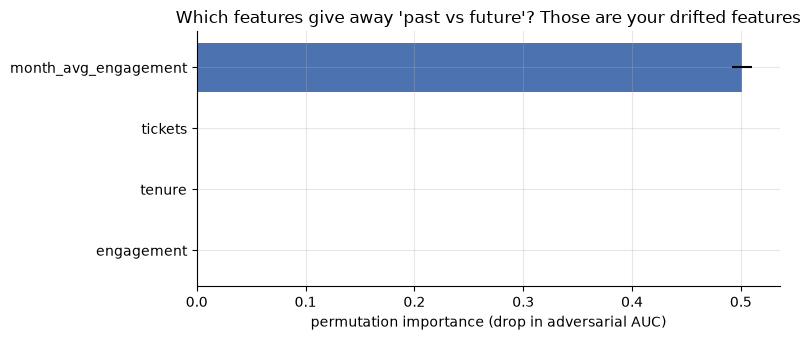

In [19]:
adv_tr, adv_te, yadv_tr, yadv_te = train_test_split(
    adv_X, adv_y, test_size=0.3, stratify=adv_y, random_state=42
)
adv_fit = HistGradientBoostingClassifier(random_state=42).fit(adv_tr, yadv_tr)
imp = permutation_importance(
    adv_fit, adv_te, yadv_te, scoring="roc_auc", n_repeats=10, random_state=42
)

order = np.argsort(imp.importances_mean)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(
    np.array(adv_features)[order],
    imp.importances_mean[order],
    xerr=imp.importances_std[order],
    color="#4c72b0",
)
ax.set_xlabel("permutation importance (drop in adversarial AUC)")
ax.set_title("Which features give away 'past vs future'? Those are your drifted features")
plt.tight_layout()
plt.show()

In [20]:
# The aggregate is a month fingerprint (18 distinct training values, 6 unseen production
# values — a tree separates them perfectly). Drop it and re-run to measure the *genuine*
# row-level covariate shift that remains.
adv_features_row = ["engagement", "tenure", "tickets"]
adv_auc_row = cross_val_score(
    adv_model,
    adv_X[adv_features_row],
    adv_y,
    cv=cv5,
    scoring="roc_auc",
).mean()
print(f"Adversarial AUC without the aggregate column : {adv_auc_row:.3f}")
print("Residual signal = real distribution shift in row-level engagement (the AR(1) market shock).")

Adversarial AUC without the aggregate column : 0.521
Residual signal = real distribution shift in row-level engagement (the AR(1) market shock).


The workflow that just played out is the one to describe in interviews:

1. **Detect**: adversarial AUC far above 0.5 → train and test are not exchangeable;
   random CV on this data answers the wrong question.
2. **Diagnose**: permutation importance names the offenders. Near-perfect separability
   (AUC ≈ 1.0) points to fingerprint columns — IDs, timestamps, per-period aggregates —
   rather than broad shift; after removing them, the remaining AUC quantifies the
   genuine covariate drift (here: a real but modest shift in `engagement`, driven by
   the simulated market shock — most of the alarm was one fingerprint column).
3. **Act**: fix the split (validate like the future), then decide per flagged feature —
   drop it, re-normalize it within period (ranks/z-scores), or re-derive it point-in-time
   if the shift is an ETL artifact.
4. **Exploit**: rank training rows by p(test-like) and validate on the most test-like
   ones (Exercise 3 — the standard Kaggle move when the test set is known to differ).
5. **Keep monitoring**: adversarial AUC between training data and live traffic is a
   deployable drift alarm — see [../10_ml_in_production/01_drift_monitoring.ipynb](../10_ml_in_production/01_drift_monitoring.ipynb).

## 11. Pitfalls that don't fit the five families

Two more evaluation-integrity failures you will meet in real code reviews. Both are
"leaks in the procedure", so both are demonstrable on pure noise.

**Pitfall A — resampling before splitting.** Random-oversampling (or SMOTE) applied
before CV puts *copies of the same row* on both sides of every split; the model then
"predicts" rows it has memorized verbatim. On noise this manufactures near-perfect AUC.
(Class imbalance done right — including why you often don't need resampling at all — is
[04_imbalanced_fraud.ipynb](04_imbalanced_fraud.ipynb).)

In [21]:
n_p, p_p = 1_500, 20
X_imb = rng.normal(size=(n_p, p_p))
y_imb = rng.binomial(1, 0.08, size=n_p)  # ~8% positives, NO signal anywhere

# WRONG: oversample the minority class first, then cross-validate
pos_idx = np.flatnonzero(y_imb == 1)
boot = rng.choice(pos_idx, size=8 * pos_idx.size, replace=True)
X_over = np.vstack([X_imb, X_imb[boot]])
y_over = np.r_[y_imb, y_imb[boot]]

rf_small = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
auc_oversample_wrong = cross_val_score(
    rf_small, X_over, y_over, cv=cv5, scoring="roc_auc"
).mean()

# RIGHT: no duplicates across folds; handle imbalance inside the model
rf_weighted = RandomForestClassifier(
    n_estimators=150, class_weight="balanced", random_state=42, n_jobs=-1
)
auc_oversample_right = cross_val_score(
    rf_weighted, X_imb, y_imb, cv=cv5, scoring="roc_auc"
).mean()

print(f"Oversample-then-split CV AUC on pure noise : {auc_oversample_wrong:.3f}")
print(f"Honest CV AUC (weights inside the folds)   : {auc_oversample_right:.3f}")

Oversample-then-split CV AUC on pure noise : 1.000
Honest CV AUC (weights inside the folds)   : 0.514


**Pitfall B — the holdout that stopped being a holdout.** Every decision you make by
looking at a holdout score spends some of its validity. Evaluate 150 candidate feature
subsets on the *same* 100-row holdout and pick the best: on pure noise, the winning
holdout score looks like real signal, and only genuinely fresh data reveals the truth.
This is the winner's curse from Section 9 wearing a different hat — and the smaller the
holdout and the more decisions it referees, the worse it gets.

In [22]:
n_h, p_h = 350, 40
X_h = rng.normal(size=(n_h, p_h))
y_h = rng.binomial(1, 0.5, size=n_h)
X_fresh = rng.normal(size=(400, p_h))       # untouched data, same (null) distribution
y_fresh = rng.binomial(1, 0.5, size=400)

fit_sl, ho_sl = slice(0, 250), slice(250, 350)  # 250 to fit, 100 as the reused holdout
best = {"auc": -np.inf}
for _ in range(150):
    cols = rng.choice(p_h, size=8, replace=False)
    m = LogisticRegression(max_iter=2_000).fit(X_h[fit_sl][:, cols], y_h[fit_sl])
    auc_ho = roc_auc_score(y_h[ho_sl], m.predict_proba(X_h[ho_sl][:, cols])[:, 1])
    if auc_ho > best["auc"]:
        best = {"auc": auc_ho, "model": m, "cols": cols}

auc_fresh = roc_auc_score(
    y_fresh, best["model"].predict_proba(X_fresh[:, best["cols"]])[:, 1]
)
print(f"Best-of-150 holdout AUC (pure noise) : {best['auc']:.3f}   <- selection bias, not signal")
print(f"Same model on untouched fresh data   : {auc_fresh:.3f}")

Best-of-150 holdout AUC (pure noise) : 0.629   <- selection bias, not signal
Same model on untouched fresh data   : 0.498


## 12. Interview corner

**Q1. "Cross-validation says 0.95 AUC; production says 0.70. Walk me through your debugging."**
Structure the answer as *measurement → data leaks → split design → shift*:
1. *Same question?* Confirm metric, population, label definition, and label maturity
   match (production labels may be immature or a different segment mix); confirm the
   production number isn't computed on a thresholded decision while CV used ranks.
2. *Leaks in the data*: audit feature timestamps vs prediction time (point-in-time
   correctness), hunt post-outcome features (univariate AUC scan, one dominant feature
   in importance); check ETL joins that read "latest" values instead of as-of values.
3. *Leaks in the procedure*: preprocessing/encoding/selection fit outside folds,
   duplicates or shared entities straddling splits, resampling before splitting,
   tuning decisions made on the reported score (no nesting/holdout).
4. *Split ≠ deployment*: time-ordered data with shuffled CV, new-entity serving with
   row-wise CV. Rebuild validation to mirror deployment (train past → score future,
   groups intact) and see if the rebuilt estimate reconciles with 0.70.
5. *Distribution shift*: adversarial validation between training data and recent
   production traffic; inspect which features moved. Also: 0.95 AUC on a business
   problem is itself a smell — say so.

**Q2. "How do you split churn data for modeling?"**
Time-based and entity-aware. Choose a prediction moment (e.g., first of month), build
features from data strictly before it (point-in-time joins), define the label over the
following window, and require the label window to have fully matured before the
training cutoff. Validate train-on-past → predict-future with rolling origins; keep all
rows of a customer on one side of every temporal boundary; hyperparameter tuning inside
the training windows only; hold out the final untouched period for the headline number.
Never shuffled row-wise KFold: it mixes future into past *and* the same customer into
both sides.

**Q3. "Give three real-pipeline examples of target leakage."**
- *Churn*: `retention_offer_sent` / "spoke to saves team" — driven by the customer's
  announced intent to cancel, i.e., by the outcome (our Section 2 demo).
- *Fraud*: `account_frozen`, `chargeback_count`, "number of manual-review notes" —
  written to the record *because* fraud was detected; at scoring time they're empty.
- *Credit default*: features pulled from the loan-servicing system (missed payments,
  collections calls) attached to historical applications — they only exist because the
  loan was booked and later went bad; at application time you have none of them.
- Bonus meta-answer: most leakage enters through ETL "latest snapshot" joins rather than
  point-in-time ("as-of") joins — this is exactly the problem feature stores solve.

**Q4. "Is it ever OK to fit a scaler on the full dataset before splitting?"**
Quantitatively it barely matters for unsupervised, smooth statistics on i.i.d. data (we
measured ≈ no inflation) — but it's still wrong, because (a) the habit doesn't survive
contact with steps that see `y` (selection inflated pure noise to ~0.8 in our demo), and
(b) a fitted `Pipeline` gives the honest version for free. Senior answer: know the
severity gradient, then follow the rule anyway because structure beats vigilance.

**Q5. "Why does out-of-fold target encoding still slightly leak, and what's fully clean?"**
A single OOF pass computed once on the training set is reused across every modeling
decision, so decisions (feature sets, hyperparameters) can adapt to its noise; and the
holdout transform uses full-training statistics chosen after looking at CV. Fully clean:
the encoder is a pipeline step refit within every fold (sklearn `TargetEncoder` does
internal cross-fitting), plus smoothing for rare levels, plus a final untouched holdout.

**Q6. "When do you reach for nested CV, and when is it overkill?"**
Reach for it when the number of tuning configurations is large relative to the data (the
winner's-curse bias we measured), when you must *report* an unbiased generalization
estimate (papers, go/no-go decisions), or when comparing model families each with its own
tuning. Overkill when data is plentiful and the config count is small — a single
untouched holdout, used once, buys nearly the same honesty at a fifth of the compute.

## 13. Key takeaways

- Leakage = information at training/evaluation time that won't exist (or will differ) at
  serving time. The estimate inflates; sometimes the model itself also gets worse
  (target leakage, naive target encoding).
- CV hygiene cannot catch leaks that live **in the data** (post-outcome features). Those
  need point-in-time feature discipline and detection heuristics (univariate AUC scans,
  importance sanity checks, "what process writes this column and when?").
- Preprocessing contamination has a severity gradient: `X`-only steps (scaler/imputer)
  barely move i.i.d. estimates; anything that sees `y` (selection, encoding, resampling)
  can turn pure noise into a publishable AUC.
- The splitter is a simulation of deployment: future-facing → time-based splits;
  repeated entities → group-aware splits; both → both. Stratification is a variance
  tool, never a substitute for honesty.
- `Pipeline` + `ColumnTransformer` + `cross_val_score` on raw columns makes procedural
  leakage structurally impossible and eliminates train/serve preprocessing skew.
- Every selection you make on a score biases that score upward (hyperparameters, feature
  subsets, repeated holdout peeks). Tune inside, report outside — nested CV or a
  once-touched holdout.
- Adversarial validation is the cheapest honest answer to "is my validation set like my
  test set?" — and it names the drifted features.
- The number to be proud of is not the highest offline AUC; it's the smallest gap between
  the offline estimate and production reality.

## 14. Exercises

**Exercise 1.** In the group-leakage demo (Section 5), `GroupKFold` keeps accounts intact
but ignores class balance. Use `StratifiedGroupKFold` and compare (a) the spread of
fold-level event rates and (b) mean AUC, against plain `GroupKFold`. Does stratification
change the honesty of the estimate or just its variance?

**Exercise 2.** Sweep the smoothing strength `m` in the target encoder
(`m ∈ {0, 2, 5, 20, 100, 1000}`) on the Section 6 data. For each `m`, fit the encoding
map on the training set and measure two things: (a) the encoded feature's **standalone
AUC** on the holdout and (b) its **correlation with the true simulated campaign effect**
(we have ground truth!). Before running it, predict which curve will move more — the
answer surprises most people.

**Exercise 3.** Adversarial validation as a *validation-set designer*: using out-of-fold
adversarial scores from Section 10, mark the 25% most production-like dev rows as the
validation set, train on the rest, and compare that validation estimate to (a) a
same-sized random validation split and (b) true production AUC. Which offline estimate
would have set expectations correctly?

In [23]:
# --- Solution 1 ---
gkf = GroupKFold(n_splits=5)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def fold_event_rates(splitter, X, y, groups):
    return np.array([y[te].mean() for _, te in splitter.split(X, y, groups)])

rates_gkf = fold_event_rates(gkf, X4, y4, user_id)
rates_sgkf = fold_event_rates(sgkf, X4, y4, user_id)
auc_sgkf = cross_val_score(
    rf, X4, y4, cv=sgkf, groups=user_id, scoring="roc_auc"
).mean()

print(f"fold event rates, GroupKFold           : {np.round(rates_gkf, 3)}  (sd {rates_gkf.std():.4f})")
print(f"fold event rates, StratifiedGroupKFold : {np.round(rates_sgkf, 3)}  (sd {rates_sgkf.std():.4f})")
print(f"mean AUC GroupKFold           : {auc_group_kfold:.3f}")
print(f"mean AUC StratifiedGroupKFold : {auc_sgkf:.3f}")
print("Stratification tightens fold composition (lower variance); honesty comes from the")
print("grouping — both estimates sit far below the leaky row-wise number.")

fold event rates, GroupKFold           : [0.259 0.288 0.284 0.233 0.27 ]  (sd 0.0196)
fold event rates, StratifiedGroupKFold : [0.27  0.27  0.259 0.269 0.266]  (sd 0.0042)
mean AUC GroupKFold           : 0.607
mean AUC StratifiedGroupKFold : 0.589
Stratification tightens fold composition (lower variance); honesty comes from the
grouping — both estimates sit far below the leaky row-wise number.


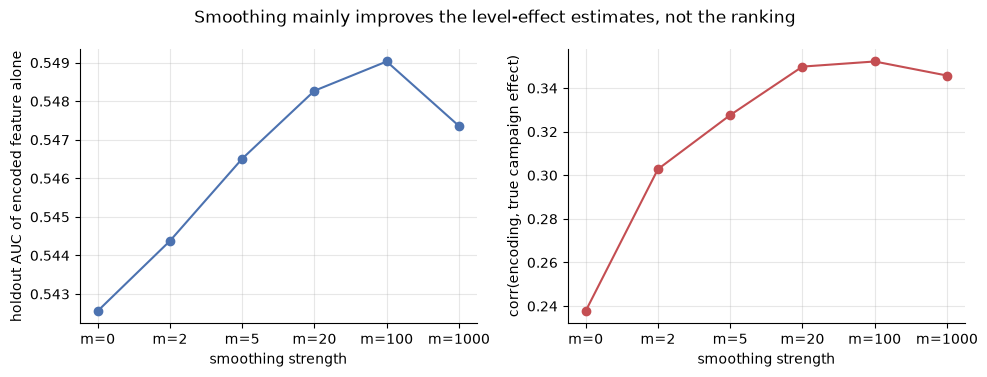

holdout AUC by m : {'0': np.float64(0.543), '2': np.float64(0.544), '5': np.float64(0.547), '20': np.float64(0.548), '100': np.float64(0.549), '1000': np.float64(0.547)}
corr with truth  : {'0': np.float64(0.238), '2': np.float64(0.303), '5': np.float64(0.328), '20': np.float64(0.35), '100': np.float64(0.352), '1000': np.float64(0.346)}
Ranking (AUC) barely moves: shrinkage toward a constant is close to a monotone
transform, and AUC only sees ranks. What smoothing really buys is much better
*estimates* of the level effects (corr with truth rises steeply from m=0, peaks
around m~20-100, and dips once heavy shrinkage reweights levels by their counts).
That matters for calibration, for downstream models that use magnitudes, and for
rare levels — which is exactly where the naive encoder leaks worst.


In [24]:
# --- Solution 2 ---
# The true campaign effect is known in simulation, so we can score the encoding directly.
true_effect = pd.Series(
    campaign_effect, index=[f"camp_{c:04d}" for c in range(n_campaigns)]
)
m_grid = [0.0, 2.0, 5.0, 20.0, 100.0, 1000.0]
auc_by_m, corr_by_m = [], []
for m in m_grid:
    map_m, prior_m = fit_encoding_map(train5, "campaign", "churned", m=m)
    ho_enc = hold5["campaign"].map(map_m).fillna(prior_m)
    auc_by_m.append(roc_auc_score(hold5["churned"], ho_enc))
    corr_by_m.append(np.corrcoef(map_m, true_effect.loc[map_m.index])[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(range(len(m_grid)), auc_by_m, marker="o")
axes[0].set_ylabel("holdout AUC of encoded feature alone")
axes[1].plot(range(len(m_grid)), corr_by_m, marker="o", color="#c44e52")
axes[1].set_ylabel("corr(encoding, true campaign effect)")
for ax in axes:
    ax.set_xticks(range(len(m_grid)), [f"m={m:g}" for m in m_grid])
    ax.set_xlabel("smoothing strength")
fig.suptitle("Smoothing mainly improves the level-effect estimates, not the ranking")
plt.tight_layout()
plt.show()
print("holdout AUC by m :", dict(zip([f"{m:g}" for m in m_grid], np.round(auc_by_m, 3))))
print("corr with truth  :", dict(zip([f"{m:g}" for m in m_grid], np.round(corr_by_m, 3))))
print("Ranking (AUC) barely moves: shrinkage toward a constant is close to a monotone")
print("transform, and AUC only sees ranks. What smoothing really buys is much better")
print("*estimates* of the level effects (corr with truth rises steeply from m=0, peaks")
print("around m~20-100, and dips once heavy shrinkage reweights levels by their counts).")
print("That matters for calibration, for downstream models that use magnitudes, and for")
print("rare levels — which is exactly where the naive encoder leaks worst.")

In [25]:
# --- Solution 3 ---
# Out-of-fold adversarial scores for every row (dev rows are the first len(dev3) rows).
adv_oof = cross_val_predict(
    HistGradientBoostingClassifier(random_state=42),
    adv_X, adv_y, cv=cv5, method="predict_proba",
)[:, 1]
dev_scores = adv_oof[: len(dev3)]

cut = np.quantile(dev_scores, 0.75)
adv_val_mask = dev_scores >= cut  # the 25% most production-like dev rows

def estimate_and_reality(val_mask, tag):
    tr, va = dev3[~val_mask], dev3[val_mask]
    g = HistGradientBoostingClassifier(random_state=42)
    g.fit(tr[features3], tr["churned"])
    est = roc_auc_score(va["churned"], g.predict_proba(va[features3])[:, 1])
    real = roc_auc_score(prod3["churned"], g.predict_proba(prod3[features3])[:, 1])
    print(f"{tag}: validation estimate {est:.3f} | actual production {real:.3f} "
          f"| gap {est - real:+.3f}")

rand_val_mask = np.zeros(len(dev3), dtype=bool)
rand_val_mask[rng.choice(len(dev3), size=adv_val_mask.sum(), replace=False)] = True

estimate_and_reality(rand_val_mask, "random validation set     ")
estimate_and_reality(adv_val_mask, "adversarial validation set")
print("The adversarially chosen validation set (mostly late, shifted months) gives the")
print("estimate that would have set production expectations correctly.")

random validation set     : validation estimate 0.713 | actual production 0.622 | gap +0.091


adversarial validation set: validation estimate 0.616 | actual production 0.634 | gap -0.018
The adversarially chosen validation set (mostly late, shifted months) gives the
estimate that would have set production expectations correctly.
